# GreenChef AI — patobulintas modelis (DistilBERT)

Ši knygelė apmoko **DistilBERT** modelį ingredientų eilutėms klasifikuoti (mėsa, žuvis, pieno produktai,
kiaušiniai, medus, augalinis) ir palygina jį su **baziniu** modeliu **TF-IDF + LogisticRegression**,
kaip reikalauja metodikos 3 ir 4 skyriai.

**Kaip paleisti (≈ 20–30 min.):**
1. Viršuje meniu **Runtime → Change runtime type → T4 GPU → Save**.
2. Meniu **Runtime → Run all**.
3. Kai 2 langelyje atsiras mygtukas **Choose Files**, pasirinkite projekto archyvą **`zalias-receptas-main.zip`**.
4. Palaukite, kol baigsis visi langeliai. Pabaigoje automatiškai atsisiųs failas **`distilbert_rezultatai.zip`** – jį atsiųskite Claude.

Jei kuris nors langelis parodo raudoną klaidą – nufotografuokite ir atsiųskite.

## 1. Nustatymai ir GPU patikrinimas

In [ ]:
# ---- NUSTATYMAI (keisti nebūtina) ----
MODEL_NAME = "distilbert-base-multilingual-cased"  # daugiakalbis: leidžia patikrinti ir LT / DE eilutes
EPOCHS     = 3        # mokymo epochos
BATCH      = 64       # paketo dydis
LR         = 5e-5     # mokymosi greitis
MAX_LEN    = 48       # maks. žetonų (tokenų) eilutėje
SEED       = 42
QUICK      = False    # True – greitas bandymas su 3000 eilučių ir 1 epocha (≈2 min.), kad patikrintumėte, ar viskas veikia

import torch, time, random, numpy as np
print("PyTorch", torch.__version__)
if torch.cuda.is_available():
    DEVICE = "cuda"
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    print("DĖMESIO: GPU neįjungtas! Runtime → Change runtime type → T4 GPU, tada Runtime → Run all.")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

## 2. Projekto įkėlimas

In [ ]:
import os, sys, glob, zipfile
from google.colab import files

if not glob.glob("/content/**/gc_core.py", recursive=True):
    print("Pasirinkite failą zalias-receptas-main.zip ...")
    up = files.upload()
    zname = next(iter(up))
    with zipfile.ZipFile(zname) as z:
        z.extractall("/content/projektas")

PROJ = os.path.dirname(glob.glob("/content/**/gc_core.py", recursive=True)[0])
os.chdir(PROJ)
sys.path.insert(0, PROJ); sys.path.insert(0, os.path.join(PROJ, "code"))
import gc_core as g
from train_model import metrics, add_typos, make_proposed   # tos pačios funkcijos kaip ataskaitoje
print("Projektas:", PROJ)

## 3. Duomenys – lygiai tas pats padalijimas kaip `code/train_model.py`

In [ ]:
import json, pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/ingredient_lines_labeled.csv").dropna(subset=["line"])
df["line"] = df["line"].astype(str)
df["x"] = df["line"].apply(g.normalize_for_model)
df = df[df.x.str.len() > 1].drop_duplicates("x").reset_index(drop=True)
tr, te = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df.label)
tr_fit, val = train_test_split(tr, test_size=0.15, random_state=SEED, stratify=tr.label)
if QUICK:
    tr_fit = tr_fit.sample(3000, random_state=SEED); EPOCHS = 1
print(f"Mokymui: {len(tr_fit)}, validacijai: {len(val)}, testui: {len(te)}")

# papildomi testai
rng = random.Random(SEED)
te_typo = te.copy(); te_typo["line"] = te_typo.line.apply(lambda s: add_typos(s, rng))
hard = pd.read_csv("data/hard_test_set.csv")
multi = pd.read_csv("data/multilingual_test_set.csv")
CATS = g.CATEGORIES
cat2id = {c: i for i, c in enumerate(CATS)}
print(tr.label.value_counts().to_dict())

## 4. Bazinis modelis: TF-IDF + LogisticRegression

In [13]:
best_C = json.load(open("data/results.json"))["best_C"]
t0 = time.time()
lr_model = make_proposed(best_C).fit(tr.x, tr.label)
lr_seconds = time.time() - t0
print(f"Apmokyta per {lr_seconds:.1f} s (C = {best_C})")

def lr_proba(lines):
    p = lr_model.predict_proba([g.normalize_for_model(l) for l in lines])
    order = [list(lr_model.classes_).index(c) for c in CATS]
    return p[:, order]

Apmokyta per 25.6 s (C = 30.0)


## 5. Patobulintas modelis: DistilBERT

In [14]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score
from torch.utils.data import DataLoader, TensorDataset

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=len(CATS)).to(DEVICE)

def encode(lines):
    e = tok(list(lines), truncation=True, max_length=MAX_LEN, padding="max_length", return_tensors="pt")
    return e["input_ids"], e["attention_mask"]

ids, mask = encode(tr_fit.line)
y = torch.tensor([cat2id[c] for c in tr_fit.label])
train_dl = DataLoader(TensorDataset(ids, mask, y), batch_size=BATCH, shuffle=True)

# klasių svoriai (kaip class_weight='balanced' baziniame modelyje)
w = compute_class_weight("balanced", classes=np.array(CATS), y=tr_fit.label.values)
loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float).to(DEVICE))
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
steps = EPOCHS * len(train_dl)
sched = get_linear_schedule_with_warmup(opt, int(0.06 * steps), steps)

@torch.no_grad()
def bert_proba(lines, bs=256, mdl=None, dev=None):
    mdl = mdl or model; dev = dev or DEVICE
    mdl.eval(); out = []
    lines = list(lines)
    for i in range(0, len(lines), bs):
        a, m = encode(lines[i:i + bs])
        logits = mdl(input_ids=a.to(dev), attention_mask=m.to(dev)).logits
        out.append(torch.softmax(logits, -1).cpu().numpy())
    return np.concatenate(out)

history, best_f1, best_state = [], -1, None
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    model.train(); tot = 0
    for a, m, yy in train_dl:
        opt.zero_grad()
        logits = model(input_ids=a.to(DEVICE), attention_mask=m.to(DEVICE)).logits
        loss = loss_fn(logits, yy.to(DEVICE)); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step(); tot += loss.item()
    vp = bert_proba(val.line)
    vf1 = f1_score(val.label, [CATS[i] for i in vp.argmax(1)], average="macro")
    history.append({"epoch": ep, "train_loss": tot / len(train_dl), "val_f1": vf1})
    print(f"Epocha {ep}: nuostolis {tot / len(train_dl):.4f}, validacijos F1 (macro) = {vf1:.4f}")
    if vf1 > best_f1:
        best_f1 = vf1
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
bert_seconds = time.time() - t0
model.load_state_dict(best_state)
print(f"Mokymas truko {bert_seconds / 60:.1f} min. Geriausias validacijos F1 = {best_f1:.4f}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epocha 1: nuostolis 0.3715, validacijos F1 (macro) = 0.9768
Epocha 2: nuostolis 0.0372, validacijos F1 (macro) = 0.9827
Epocha 3: nuostolis 0.0182, validacijos F1 (macro) = 0.9845
Mokymas truko 10.6 min. Geriausias validacijos F1 = 0.9845


## 6. Vertinimas: testas, rašybos klaidos, sunkūs pavyzdžiai, kitos kalbos

In [15]:
def hybrid(lines, proba, thr=g.HYBRID_THRESHOLD):
    # ta pati logika kaip gc_core.classify_lines: taisyklės + DI modelis
    out = []
    for line, p in zip(lines, proba):
        rule = g.expert_label(line)
        if rule != "PLANT":
            out.append(rule)
        elif CATS[p.argmax()] != "PLANT" and p.max() >= thr:
            out.append(CATS[p.argmax()])
        else:
            out.append("PLANT")
    return out

sets = {"test": te, "typo": te_typo, "hard": hard, "multilingual": multi}
res = {"model_name": MODEL_NAME, "epochs": EPOCHS, "batch": BATCH, "lr": LR, "max_len": MAX_LEN,
       "n_train": int(len(tr_fit)), "n_val": int(len(val)), "n_test": int(len(te)),
       "train_seconds_bert": bert_seconds, "train_seconds_lr": lr_seconds, "history": history,
       "best_val_f1": best_f1, "quick": QUICK}
preds_out = {}
for name, d in sets.items():
    lines = list(d.line); y_true = list(d.label)
    pl, pb = lr_proba(lines), bert_proba(lines)
    res[name] = {
        "Raktažodžiai (atskaitos)": metrics(y_true, [g.naive_label(l) for l in lines]),
        "Bazinis: TF-IDF + LogReg": metrics(y_true, [CATS[i] for i in pl.argmax(1)]),
        "Patobulintas: DistilBERT": metrics(y_true, [CATS[i] for i in pb.argmax(1)]),
        "Hibridinis: taisyklės + TF-IDF": metrics(y_true, hybrid(lines, pl)),
        "Hibridinis: taisyklės + DistilBERT": metrics(y_true, hybrid(lines, pb)),
    }
    if name != "test":
        res[name]["Ekspertinės taisyklės"] = metrics(y_true, [g.expert_label(l) for l in lines])
    if name in ("hard", "multilingual"):
        preds_out[name] = d.assign(tfidf=[CATS[i] for i in pl.argmax(1)], distilbert=[CATS[i] for i in pb.argmax(1)],
                                   distilbert_conf=pb.max(1).round(3), hybrid_bert=hybrid(lines, pb))

rows = []
for name in sets:
    for meth, m in res[name].items():
        rows.append({"rinkinys": name, "metodas": meth, "tikslumas": round(m["accuracy"], 4), "F1 (macro)": round(m["f1_macro"], 4)})
table = pd.DataFrame(rows)
table

,rinkinys,metodas,tikslumas,F1 (macro)
0,test,Raktažodžiai (atskaitos),0.9225,0.8063
1,test,Bazinis: TF-IDF + LogReg,0.9962,0.9896
2,test,Patobulintas: DistilBERT,0.9952,0.9852
3,test,Hibridinis: taisyklės + TF-IDF,0.9987,0.9971
4,test,Hibridinis: taisyklės + DistilBERT,0.9978,0.9937
5,typo,Raktažodžiai (atskaitos),0.8969,0.7223
6,typo,Bazinis: TF-IDF + LogReg,0.9811,0.9509
7,typo,Patobulintas: DistilBERT,0.9703,0.9190
8,typo,Hibridinis: taisyklės + TF-IDF,0.9800,0.9505
9,typo,Hibridinis: taisyklės + DistilBERT,0.9722,0.9298


## 7. Greitis (realaus laiko reikalavimas < 200 ms)

In [16]:
sample = list(te.line[:200])
def ms_per_line(fn):
    t0 = time.time()
    for s in sample: fn([s])
    return (time.time() - t0) / len(sample) * 1000

res["inference_ms_lr"] = ms_per_line(lr_proba)
res["inference_ms_bert_gpu"] = ms_per_line(bert_proba) if DEVICE == "cuda" else None
cpu_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=len(CATS))
cpu_model.load_state_dict(best_state); cpu_model.eval()
torch.set_num_threads(2)  # panašiai kaip paprastame nešiojamame kompiuteryje
res["inference_ms_bert_cpu"] = ms_per_line(lambda L: bert_proba(L, mdl=cpu_model, dev="cpu"))
res["model_params_millions"] = sum(p.numel() for p in model.parameters()) / 1e6
print(f"TF-IDF + LogReg: {res['inference_ms_lr']:.2f} ms/eilutei")
print(f"DistilBERT GPU:  {res['inference_ms_bert_gpu']} ms/eilutei")
print(f"DistilBERT CPU:  {res['inference_ms_bert_cpu']:.1f} ms/eilutei")
print(f"DistilBERT parametrų: {res['model_params_millions']:.0f} mln.")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


TF-IDF + LogReg: 2.74 ms/eilutei
DistilBERT GPU:  6.322879791259766 ms/eilutei
DistilBERT CPU:  92.9 ms/eilutei
DistilBERT parametrų: 135 mln.


## 8. Rezultatų išsaugojimas ir atsisiuntimas

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Atsisiųsta: distilbert_rezultatai.zip – atsiųskite šį failą Claude.


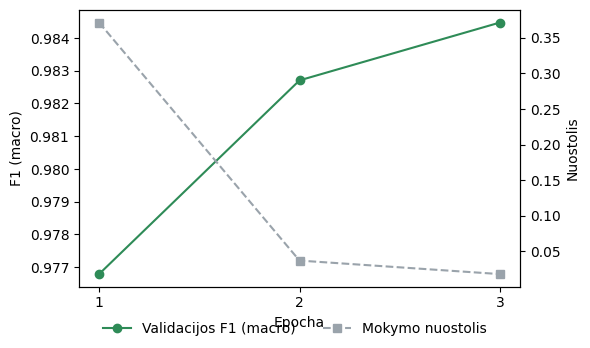

In [17]:
import matplotlib.pyplot as plt
h = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(h.epoch, h.val_f1, "o-", color="#2E8B57", label="Validacijos F1 (macro)")
ax2 = ax.twinx(); ax2.plot(h.epoch, h.train_loss, "s--", color="#9AA3AB", label="Mokymo nuostolis")
ax.set_xlabel("Epocha"); ax.set_ylabel("F1 (macro)"); ax2.set_ylabel("Nuostolis")
ax.set_xticks(h.epoch); fig.legend(loc="lower center", ncol=2, frameon=False); fig.tight_layout()
fig.savefig("distilbert_mokymas.png", dpi=150)

os.makedirs("distilbert_out", exist_ok=True)
json.dump(res, open("distilbert_out/results_distilbert.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
table.to_csv("distilbert_out/palyginimas.csv", index=False)
for k, d in preds_out.items():
    d.to_csv(f"distilbert_out/{k}_predictions_distilbert.csv", index=False)
os.replace("distilbert_mokymas.png", "distilbert_out/distilbert_mokymas.png")
with zipfile.ZipFile("/content/distilbert_rezultatai.zip", "w") as z:
    for f in glob.glob("distilbert_out/*"):
        z.write(f, os.path.basename(f))
files.download("/content/distilbert_rezultatai.zip")
print("Atsisiųsta: distilbert_rezultatai.zip – atsiųskite šį failą Claude.")

## 9. (Nebūtina) Modelio išsaugojimas Google Drive

Paties modelio (~0,5 GB) atsiųsti nereikia. Jei vėliau norėsime jį įdiegti į programėlę,
paleiskite šį langelį – modelis bus išsaugotas jūsų Google Drive aplanke `GreenChef_DistilBERT`.

In [18]:
from google.colab import drive
drive.mount("/content/drive")
out = "/content/drive/MyDrive/GreenChef_DistilBERT"
model.save_pretrained(out); tok.save_pretrained(out)
json.dump({"labels": CATS}, open(f"{out}/labels.json", "w"))
print("Išsaugota:", out)

MessageError: Error: credential propagation was unsuccessful